In [50]:
import numpy as np
import matplotlib.pyplot as plt
from double_stopping_env import HouseSellingEnv, RandomWalk
import visualizer
from tabulate import tabulate
from tqdm import tqdm

In [51]:
def plot_q_history_for_state(Q_values_history, state, time, env, title=None):
    """
    Plot the evolution of Q-values across training updates for a given state,
    showing separate lines for each (action, z) pair, each in a different color.

    Parameters:
    -----------
    Q_values_history : list of np.ndarray
        History of Q-arrays from the agent, each of shape (T, S, 2, A)
    state : int
        The state index to visualize
    time : int
        The time step to visualize
    env : environment object
        Should have .states (list of state values) and .actions (list of action names)
    title : str, optional
        Custom title for the plot

    Returns:
    --------
    fig, ax : matplotlib figure and axis
    """
    num_updates = len(Q_values_history)
    action_names = env.actions
    num_actions = len(action_names)
    z_values = [1, 2]  # z=1 means one stopping left, z=2 means two stoppings left

    fig, ax = plt.subplots(figsize=(12, 6))
    # Use a color for each (action, z) pair
    import matplotlib.cm as cm

    num_lines = num_actions * len(z_values)
    color_map = cm.get_cmap("tab10", num_lines)
    line_idx = 0

    for a_idx, action_name in enumerate(action_names):
        for z_index, z in enumerate(z_values):
            values = [Q[time, state, z_index, a_idx] for Q in Q_values_history]
            label = f"Action: {action_name}, z={z}"
            ax.plot(
                range(num_updates),
                values,
                color=color_map(line_idx),
                linestyle="-",
                label=label,
            )
            line_idx += 1

    ax.set_xlabel("Update Step")
    ax.set_ylabel("Q-Value")
    ax.set_title(
        title or f"Q-Value History for State {state} (Value: {env.states[state]})"
    )
    ax.grid(True, linestyle="--", alpha=0.7)
    ax.legend()
    plt.tight_layout()
    return fig, ax

def plot_q_values(Q, state, env, title=None):
    """
    Plot Q-values for a specific state across all time steps, actions, and z-values.
    Each (action, z) pair uses a different color.
    """
    horizon = Q.shape[0]
    action_names = env.actions
    num_actions = len(action_names)

    fig, ax = plt.subplots(figsize=(12, 6))
    time_steps = np.arange(horizon)
    # Use 4 distinct colors for the 4 (action, z) pairs
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    line_idx = 0

    for a_idx, action_name in enumerate(action_names):
        for z_index, z_val in enumerate([1, 2]):  # z=1 then z=2
            color = colors[line_idx % len(colors)]
            ax.plot(
                time_steps,
                Q[:, state, z_index, a_idx],
                marker="o",
                label=f"Action: {action_name}, z={z_val}",
                color=color,
            )
            line_idx += 1

    ax.set_xlabel("Time Step")
    ax.set_ylabel("Q-Value")
    ax.set_title(title or f"Q-values for State {state} (Value: {env.states[state]})")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.7)
    plt.tight_layout()
    return fig, ax

In [52]:
class QLearning:
    def __init__(self, env, epsilon=1, gamma=1, episodes=100000, alpha=0.1):
        self.env = env
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.episodes = episodes
        self.actions = [0, 1]  # 0 = Continue, 1 = Stop
        self.start_states = []
        self.ep_rewards = []

        self.Q = np.zeros(
            (self.env.horizon + 1, len(self.env.states), 2, 2)
        )  # time x state x stops_available (1 or 2) x actions
        self.Q_values_history = np.zeros(
            (self.episodes, self.env.horizon + 1, len(self.env.states), 2, 2)
        )
        for t in range(self.env.horizon):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    self.Q[t, s, z - 1, 1] = s - (z - 1) * self.env.cost  # Stop

        self.Q[self.env.horizon, :, :, :] = 0  # no values after the last time step

        self.training_regret = []
        self.optimal_policy = None

    def greedy(self, t, s, z):
        max = np.max(self.Q[t, s, z - 1])
        max_actions = np.argwhere(self.Q[t, s, z - 1] == max).flatten()
        if len(max_actions) > 1:
            return np.random.choice(max_actions)
        else:
            return max_actions[0]
        # return np.argmax(self.Q[t, s, z - 1])  # z ∈ {1,2} → index ∈ {0,1}

    def e_greedy(self, t, s, z):
        if np.random.rand() > self.epsilon:
            return self.greedy(t, s, z)
        return np.random.choice(self.actions)

    def reward(self, s, action, z):
        # if action == 0:  # Continue
        #     return -self.env.cost
        
        if action == 0:  # Continue
            return 0
        else:  # Stop
            if z == 2:  # first stop
                return s - self.env.cost
            elif z == 1:  # second stop
                return s
        return 0

    def simulate_episode(self):
        sequence = self.env.generate_sequence()
        self.start_states.append(sequence[0])  # store the first state of the episode
        z = 2  # two stops available initially
        ep_reward = 0
        for t in range(self.env.horizon):
            s = sequence[t]
            a = self.e_greedy(t, s, z)

            r = self.reward(s, a, z)
            ep_reward += r

            if t < self.env.horizon - 1:
                next_s = sequence[t + 1]
                next_z = z if a == 0 else z - 1  # if Stop, decrement available stops

                if next_z > 0:
                    next_max_q = np.max(self.Q[t + 1, next_s, next_z - 1])
                else:
                    next_max_q = 0  # no more actions after both stops

                self.Q[t, s, z - 1, a] += self.alpha * (
                    r + self.gamma * next_max_q - self.Q[t, s, z - 1, a]
                )  # number of stops available is z, so z-1 is the index

                if a == 1 and next_z == 0:
                    break  # end after 2nd stop

                z = next_z
            else:
                # last step, no next state
                self.Q[t, s, z - 1, a] += self.alpha * (r - self.Q[t, s, z - 1, a])
                break
        self.ep_rewards.append(ep_reward)
        # self.update_regret(sequence, ep_reward)

    
    
    def update_history(self, episode):
        self.Q_values_history[episode] = self.Q.copy()

    def learn(self):
        for i in tqdm(range(self.episodes), desc="Learning Progress"):
            self.simulate_episode()
            self.update_history(i)
            # self.update_loss()

        self.extract_policy()
        return self.Q, self.Q_values_history

    def extract_policy(self):
        policy = np.zeros((self.env.horizon, len(self.env.states), 2), dtype=int)
        for t in range(self.env.horizon):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    policy[t, s, z - 1] = np.argmax(self.Q[t, s, z - 1])
        self.optimal_policy = policy
        return policy

    def get_values(self):
        V_1 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        V_2 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                V_1[t, s] = max(self.Q[t, s, 0, a] for a in self.actions)
                V_2[t, s] = max(self.Q[t, s, 1, a] for a in self.actions)
        return V_1, V_2

    def get_regret(self, V_2):
        self.training_regret = np.zeros(self.episodes)
        self.testing_regret = np.zeros(self.episodes)
        for episode in range(self.episodes):
            # print(episode)
            self.training_regret[episode] = (
                # np.max(self.Q[0][self.start_states[episode], 1])
                V_2[0][self.start_states[episode]]
                - self.ep_rewards[episode]
            )
            sequence = self.env.generate_sequence()
            start_state = sequence[0]
            z = 2  # two stops available initially
            ep_reward = 0
            for t in range(self.env.horizon):
                s = sequence[t]
                a = self.greedy(t, s, z)

                r = self.reward(s, a, z)
                ep_reward += r

                if t < self.env.horizon - 1:
                    next_s = sequence[t + 1]
                    next_z = z if a == 0 else z - 1  # if Stop, decrement available stops

                    if next_z > 0:
                        next_max_q = np.max(self.Q[t + 1, next_s, next_z - 1])
                    else:
                        next_max_q = 0  # no more actions after both stops

                    if a == 1 and next_z == 0:
                        break  # end after 2nd stop
                    z = next_z
                else:
                    break
            self.testing_regret[episode] = (
                V_2[0][start_state] - ep_reward
            )
            
            
        return self.training_regret, self.testing_regret

    def get_average_rewards(self):
        self.average_rewards = np.zeros(self.episodes)
        average_reward = 0
        for episode in range(self.episodes):
            average_reward += (1 / (episode + 1)) * (
                self.ep_rewards[episode] - average_reward
            )
            self.average_rewards[episode] = average_reward
        return self.average_rewards

In [53]:
env = HouseSellingEnv(horizon=5, cost=10, max_offer=100)
Q_agent = QLearning(env, episodes=20000)
Q, history = Q_agent.learn()
V_1, V_2 = Q_agent.get_values()

Learning Progress:   0%|          | 0/20000 [00:00<?, ?it/s]

Learning Progress: 100%|██████████| 20000/20000 [00:02<00:00, 8311.90it/s]


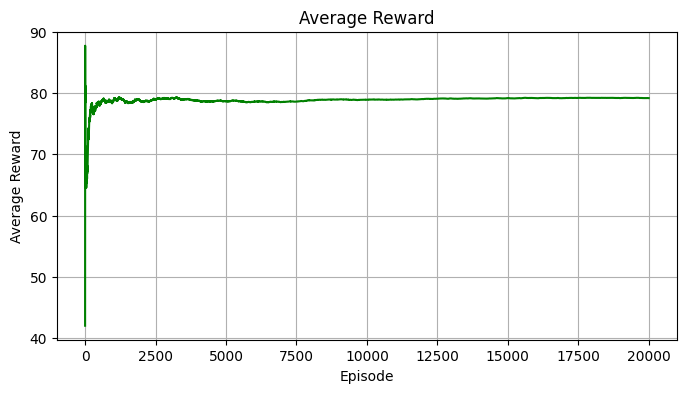

Average Reward: 79.19602479393541


In [54]:
average_rewards = Q_agent.get_average_rewards()
plt.figure(figsize=(8, 4))
plt.plot(average_rewards, color="green")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("Average Reward")
plt.grid(True)
plt.show()
print("Average Reward:", np.mean(average_rewards[-100:]))

- model based RL (tentative): getting true distribution from limited samples, then applying VI to that: UCRL (Upper Confidence), PSRL (Posterior Sampling)

next week:
- markovian envt required
- hyperparameter tuning: lr vs the distribution 
- modifying the equations for difference maximization from sum maximization -> generalised function of both the offers 

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=1, A=0      |   0 |   0 |   0 |   0 |   0 |   0 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=1, A=1      |   0 |   0 |   0 |   0 |   0 |   0 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+---------+-----+-----+-----+-----+-----+
| State, z, Action   |       0 |   1 |   2 |   3 |   4 |   5 |
+====================+=========+=====+=====+=====+=====+=====+
| S=0, z=2, A=0      | 95.2644 |   0 |   0 |   0 |   0 |   0 |
+--------------------+---------+-----+-----+-----+-----+-----+

+--------------------+---------+-----+-----+-----+-----+-----+
| State, z, Action   |       

/var/folders/js/n7mnpc4915x2hstjlmdjm3_m0000gn/T/ipykernel_64796/1803107884.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_map = cm.get_cmap("tab10", num_lines)


(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Q-Value History for State 55 (Value: 55)'}, xlabel='Update Step', ylabel='Q-Value'>)

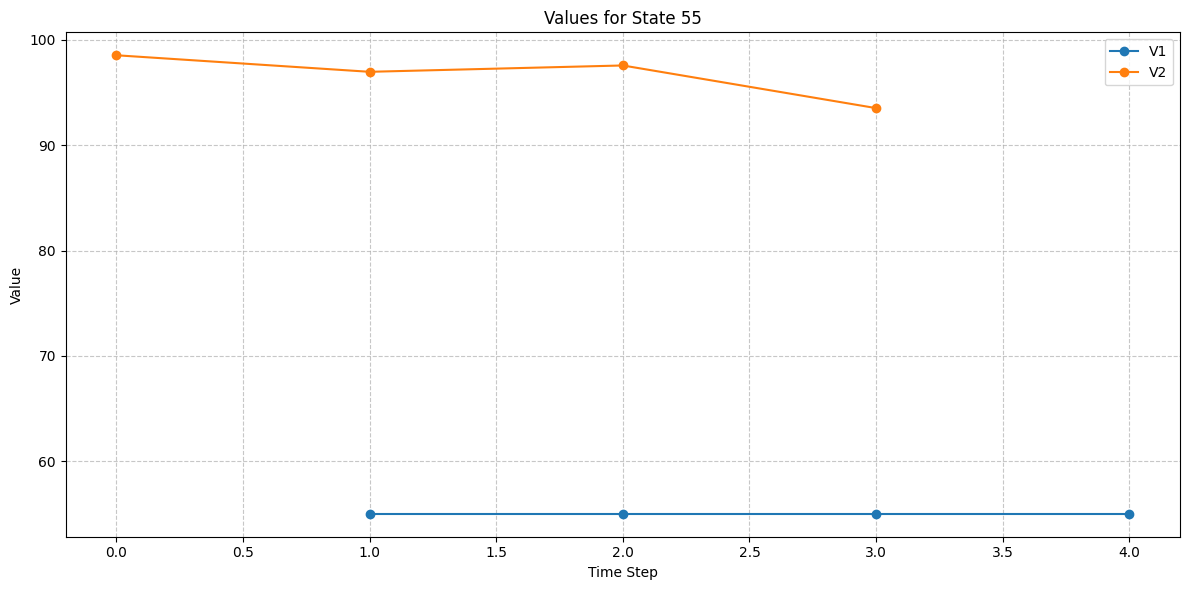

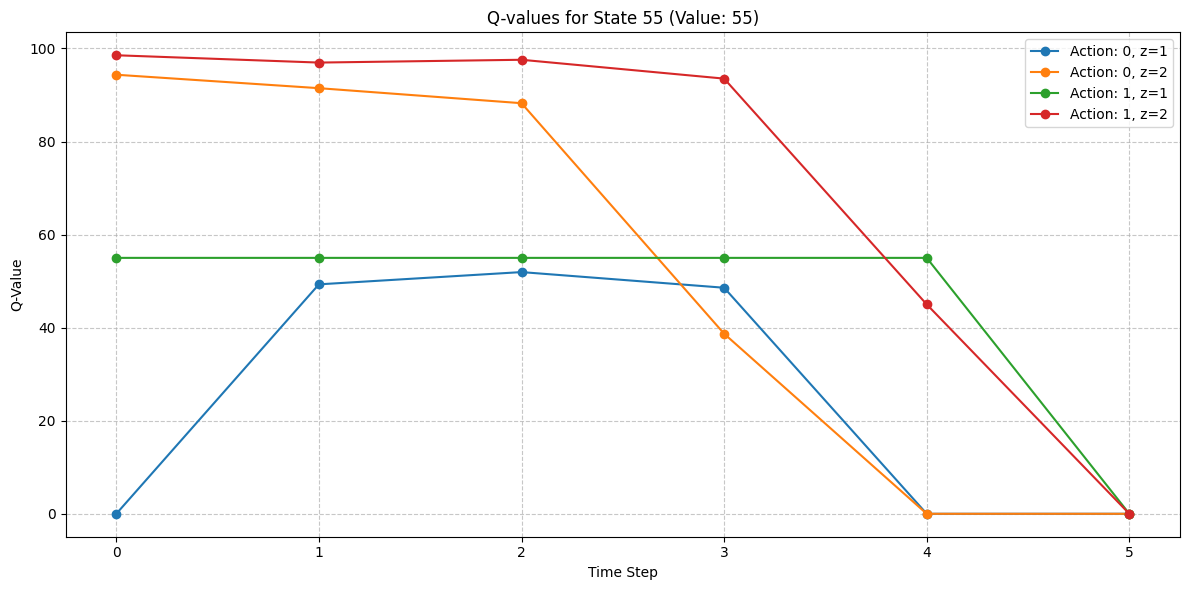

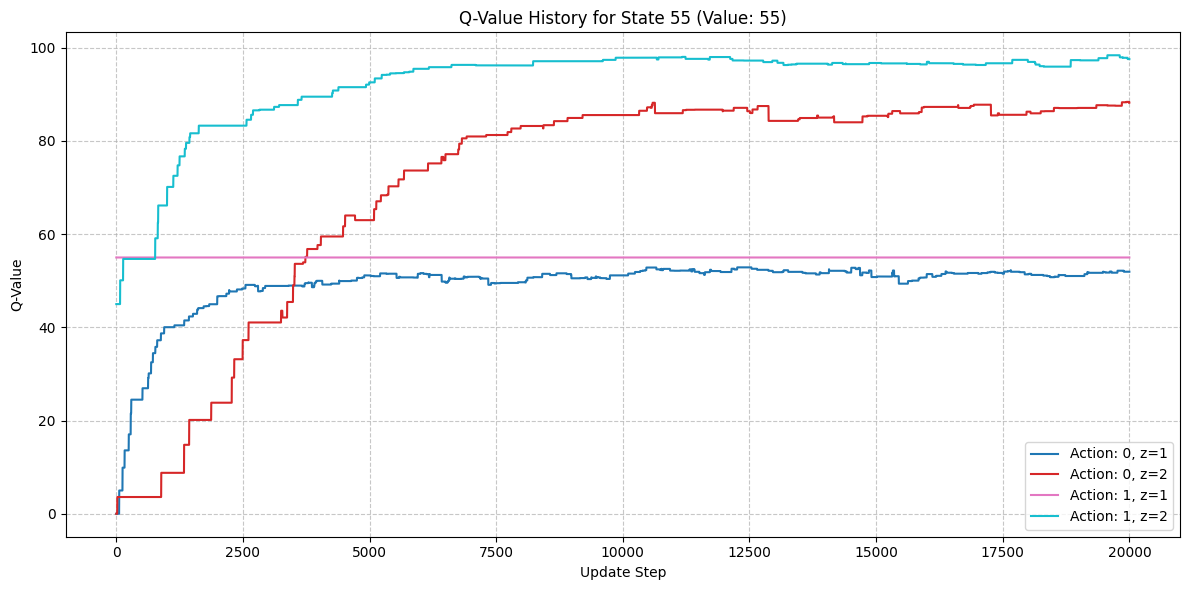

In [55]:
visualizer.plot_values(V_1, V_2, 55)
plot_q_values(Q, 55, env)
visualizer.print_q_table_all_timesteps(Q, env)
plot_q_history_for_state(history, state=55, time=2, env=env)

In [56]:
class DoubleOptimalStopping:
    def __init__(self, env):
        self.env = env
        self.N = self.env.horizon
        self.vN_1, self.vN_2 = self.dp()

    def dp(self):
        v = np.zeros((self.N + 1, 3))
        v[0, 1] = -np.inf
        v[1, 2] = 0
        for n in range(1, self.N):
            v[n, 1] = self.env.exp_max(self.N - n + 1, v[n - 1, 1])
        for n in range(2, self.N + 1):
            v[n, 2] = (
                self.env.exp_max(self.N - n + 1, v[n - 1, 1] - v[n - 1, 2])
                - self.env.exp(self.N - n + 1)
                + v[n - 1, 2]
            )

        return v[:, 1], v[:, 2]

    def plot(self):
        # N_values = np.arange(self.env.horizon + 1)
        N_values_1 = np.arange(1, self.N)
        N_values_2 = np.arange(self.N - 1)
        plt.figure(figsize=(8, 5))
        plt.plot(N_values_1, self.vN_1[1:-1], label="$v_{N,1}$", marker="o")
        plt.plot(N_values_2, self.vN_2[:-2], label="$v_{N,2}$", marker="s")
        plt.xlabel("N")
        plt.ylabel("Value")
        plt.title("Optimal Stopping Values vs. N")
        plt.legend()
        plt.grid()
        plt.show()

    def print(self):
        N_values = np.arange(self.env.horizon + 1)[::-1]
        table_data = [
            [N, v1, v2]
            for N, v1, v2 in zip((N_values), self.vN_1[::-1], self.vN_2[::-1])
        ]
        print(tabulate(table_data, headers=["N", "vN_1", "vN_2"], tablefmt="grid"))

    def get_values(self):
        V_1 = np.zeros((self.N + 1, len(self.env.states)))
        V_2 = np.zeros((self.N + 1, len(self.env.states)))

        for t in range(self.N + 1):
            for s in range(len(self.env.states)):
                V_1[t, s] = max(s, self.vN_1[self.N - (t + 1)] - self.env.cost)
                V_2[t, s] = (
                    max(self.vN_2[self.N - (t + 1)], s + self.vN_1[self.N - (t + 1)])
                    - self.env.cost
                )
        return V_1, V_2

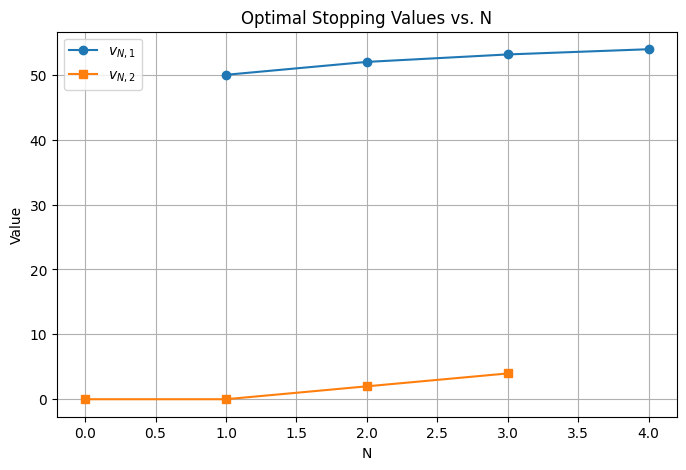

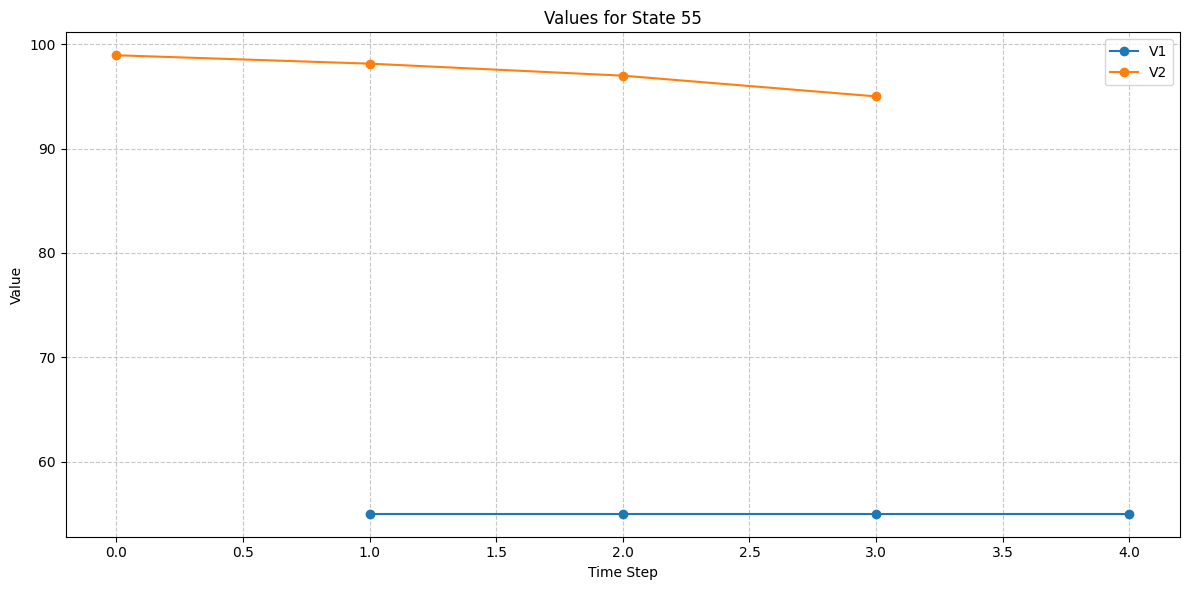

In [57]:
vi_agent = DoubleOptimalStopping(env)
vi_agent.plot()
v_N1, v_N2 = vi_agent.dp()
V_1_vi, V_2_vi = vi_agent.get_values()
visualizer.plot_values(V_1_vi, V_2_vi, 55)

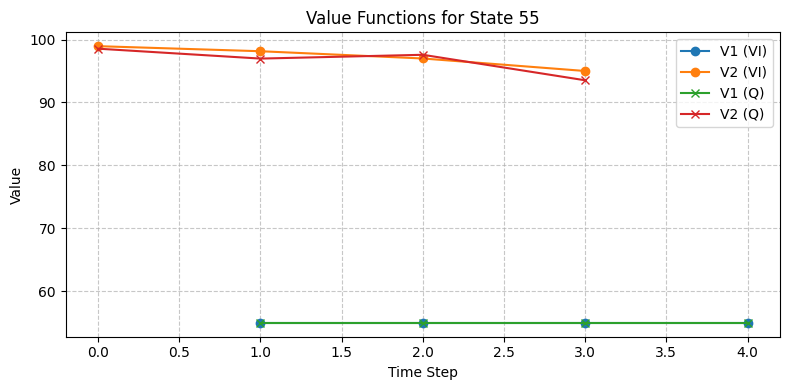

In [58]:
visualizer.plot_all_values(V_1_vi, V_2_vi, V_1, V_2, 55)

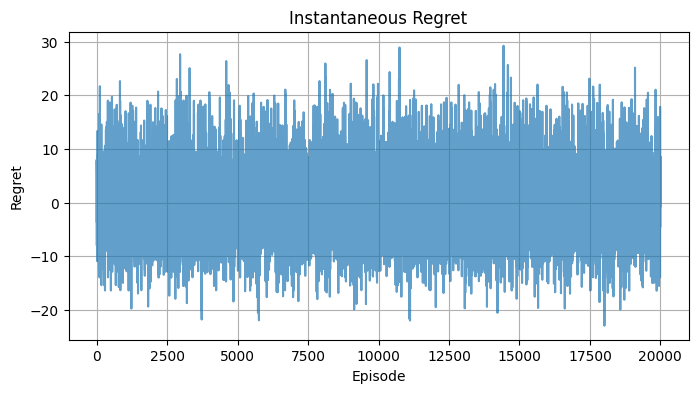

In [59]:
training_regret,testing_regret = Q_agent.get_regret(V_2)
plt.figure(figsize=(8, 4))
plt.plot(testing_regret, alpha=0.7)
plt.xlabel("Episode")
plt.ylabel("Regret")
plt.title("Instantaneous Regret")
plt.grid(True)
plt.show()

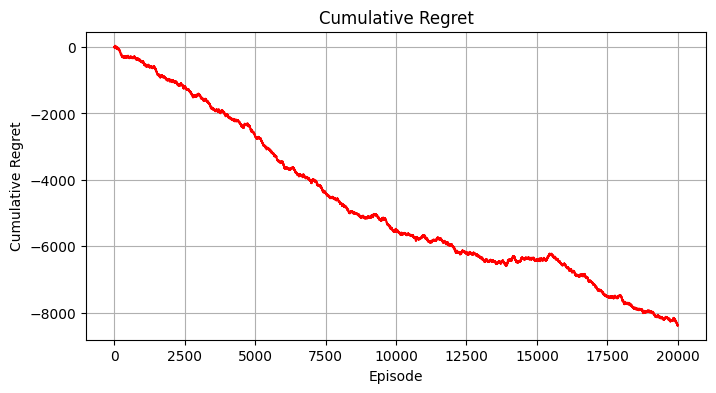

In [60]:
cum_regret = np.cumsum(testing_regret)
plt.figure(figsize=(8, 4))
plt.plot(cum_regret, color="red")
plt.xlabel("Episode")
plt.ylabel("Cumulative Regret")
plt.title("Cumulative Regret")
plt.grid(True)
plt.show()

## Markovian Envt

In [61]:

class MarkovianHouseSellingEnv:
    def __init__(self, horizon=10, cost=10, max_offer=100, alpha=1.0):
        self.horizon = horizon
        self.cost = cost
        self.max_offer = max_offer
        self.states = [i for i in range(max_offer + 1)]
        self.actions = [0, 1]  # 0: Accept, 1: Reject
        self.alpha = alpha
        self._init_probabilities()
        self._init_TPM()

    def reset(self):
        return np.random.choice(self.states, p=self.P)

    def _init_probabilities(self):
        self.P = np.zeros(self.max_offer + 1)
        mu = self.max_offer / 2
        sigma = np.sqrt(self.max_offer / 4)
        for i in range(self.max_offer + 1):
            self.P[i] = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
                -((i - mu) ** 2) / (2 * sigma**2)
            )
        self.P /= np.sum(self.P)

    def _init_TPM(self):
        """Transition matrix TPM[s][s'] = P(s' | s)"""
        self.TPM = np.zeros((self.max_offer + 1, self.max_offer + 1))
        self.P_cumsum = np.cumsum(self.P)

        for s in range(self.max_offer + 1):
            for s_prime in range(self.max_offer + 1):
                if s_prime < s:
                    self.TPM[s, s_prime] = 0
                elif s_prime == s:
                    self.TPM[s, s_prime] = self.P_cumsum[s]
                else:
                    self.TPM[s, s_prime] = self.P[s_prime]

            self.TPM[s] /= np.sum(self.TPM[s])  # Normalize each row

    def get_next_state(self, s):
        return np.random.choice(self.states, p=self.TPM[s])

    def generate_sequence(self):
        sequence = [self.reset()]
        for _ in range(1, self.horizon):
            next_state = self.get_next_state(sequence[-1])
            sequence.append(next_state)
        return sequence

    def exp_max(self, n, x, s):
        """
        Conditional expected maximum:
        E_s[max(x, S_{t+1}) | S_t = s] = sum_{s'} max(x, s') * P(s' | s)
        """
        vals = np.array([max(x, s_prime) for s_prime in self.states])
        return np.dot(vals, self.TPM[s])

    # Optional utilities if needed
    def cdf(self):
        return np.cumsum(self.P)

    def exp_indictor_less_than(self, x):
        vals = np.array([i if i <= x else 0 for i in self.states])
        return np.dot(vals, self.P)


Learning Progress: 100%|██████████| 20000/20000 [00:02<00:00, 7982.40it/s]


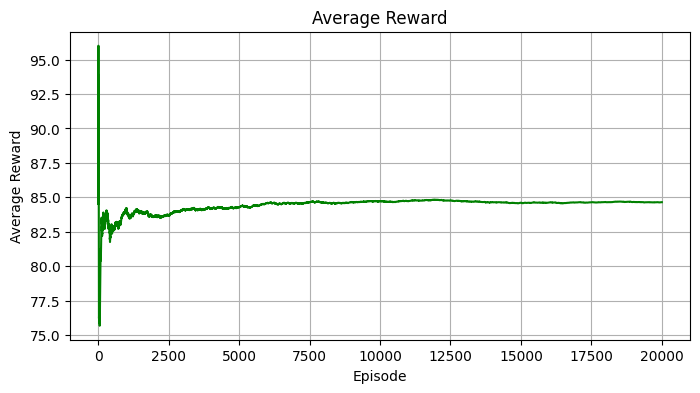

Average Reward: 84.63724214423995
+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=1, A=0      |   0 |   0 |   0 |   0 |   0 |   0 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=1, A=1      |   0 |   0 |   0 |   0 |   0 |   0 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=2, A=0      |   0 |   0 |   0 |   0 |   0 |   0 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action 

/var/folders/js/n7mnpc4915x2hstjlmdjm3_m0000gn/T/ipykernel_64796/1803107884.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_map = cm.get_cmap("tab10", num_lines)


(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Q-Value History for State 55 (Value: 55)'}, xlabel='Update Step', ylabel='Q-Value'>)

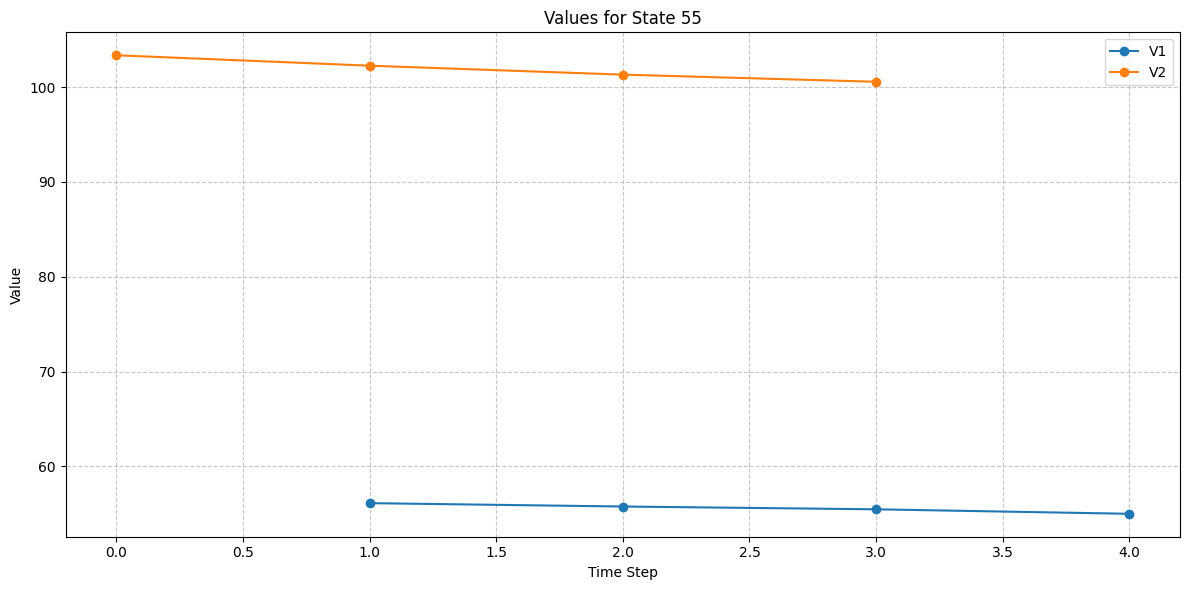

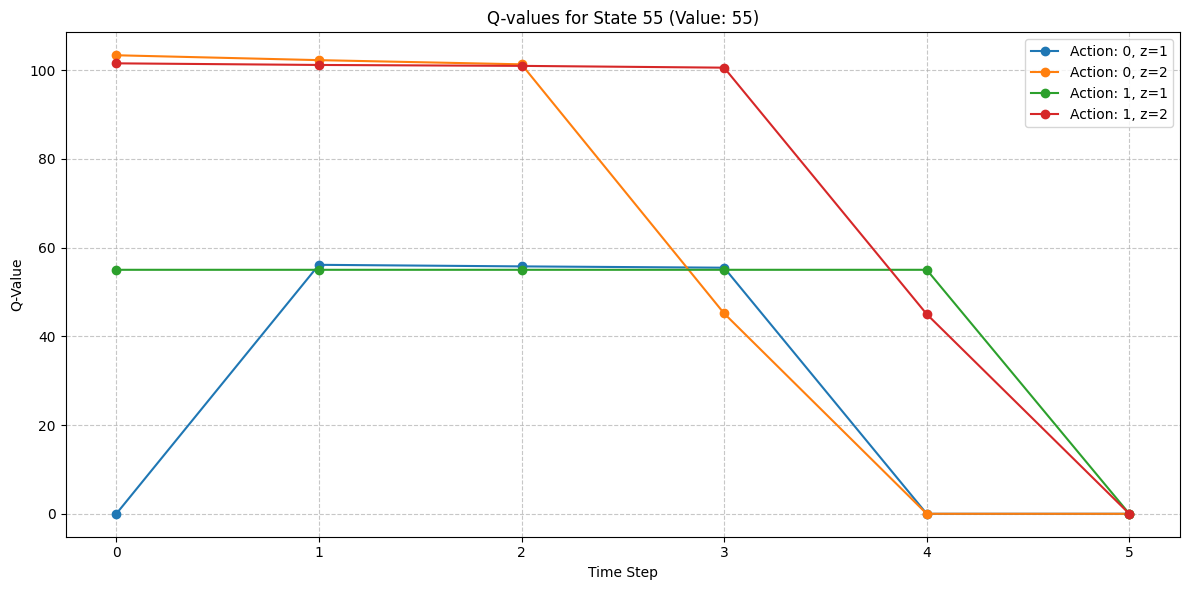

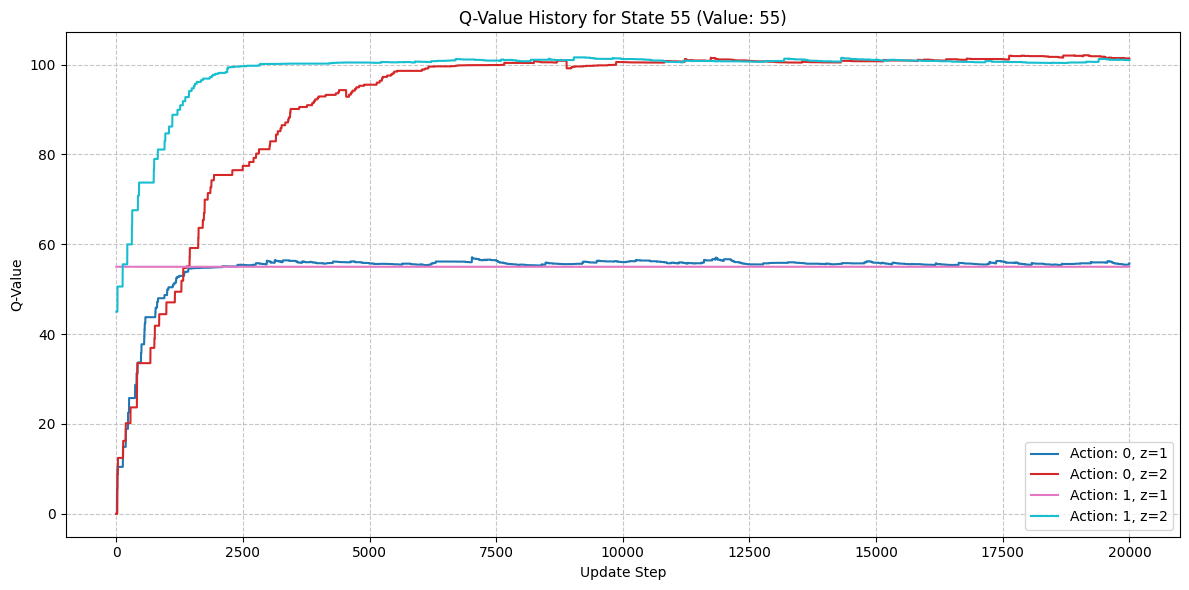

In [62]:
env2 = MarkovianHouseSellingEnv(horizon=5, cost=10, max_offer=100)
Q_agent_2 = QLearning(env2, episodes=20000)
Q_2, history_2 = Q_agent_2.learn()

V_1_2, V_2_2 = Q_agent_2.get_values()

average_rewards_2 = Q_agent_2.get_average_rewards()
plt.figure(figsize=(8, 4))
plt.plot(average_rewards_2, color="green")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("Average Reward")
plt.grid(True)
plt.show()
print("Average Reward:", np.mean(average_rewards_2[-100:]))

visualizer.plot_values(V_1_2, V_2_2, 55)
plot_q_values(Q_2, 55, env2)
visualizer.print_q_table_all_timesteps(Q_2, env2)
plot_q_history_for_state(history_2, state=55, time=2, env=env2)

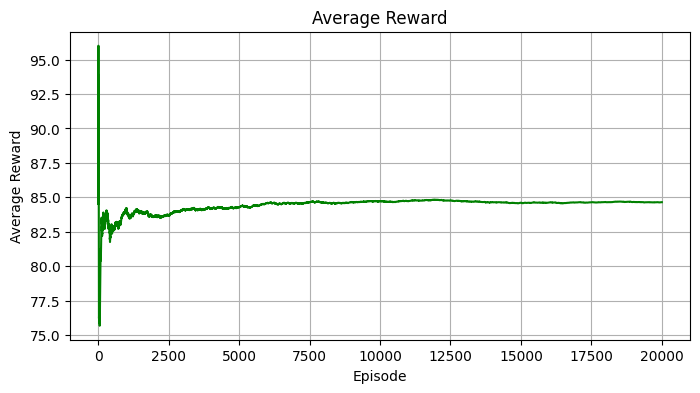

Average Reward: 84.63724214423995


In [63]:
average_rewards_2 = Q_agent_2.get_average_rewards()
plt.figure(figsize=(8, 4))
plt.plot(average_rewards_2, color="green")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("Average Reward")
plt.grid(True)
plt.show()
print("Average Reward:", np.mean(average_rewards_2[-100:]))

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=1, A=0      |   0 |   0 |   0 |   0 |   0 |   0 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=1, A=1      |   0 |   0 |   0 |   0 |   0 |   0 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=2, A=0      |   0 |   0 |   0 |   0 |   0 |   0 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 | 

/var/folders/js/n7mnpc4915x2hstjlmdjm3_m0000gn/T/ipykernel_64796/1803107884.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_map = cm.get_cmap("tab10", num_lines)


(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Q-Value History for State 55 (Value: 55)'}, xlabel='Update Step', ylabel='Q-Value'>)

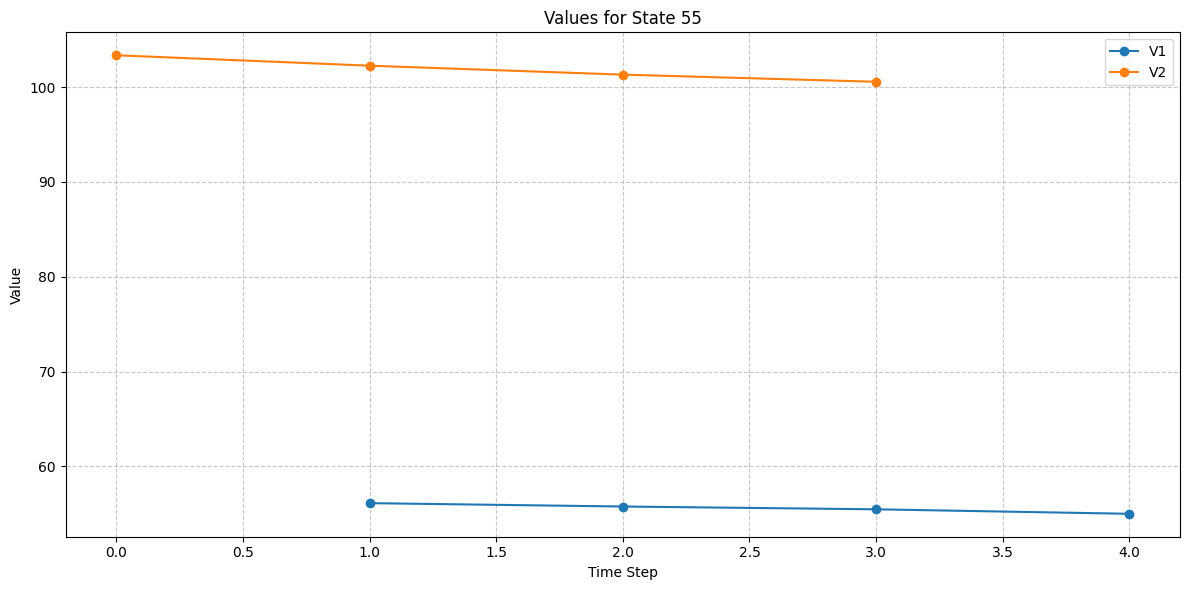

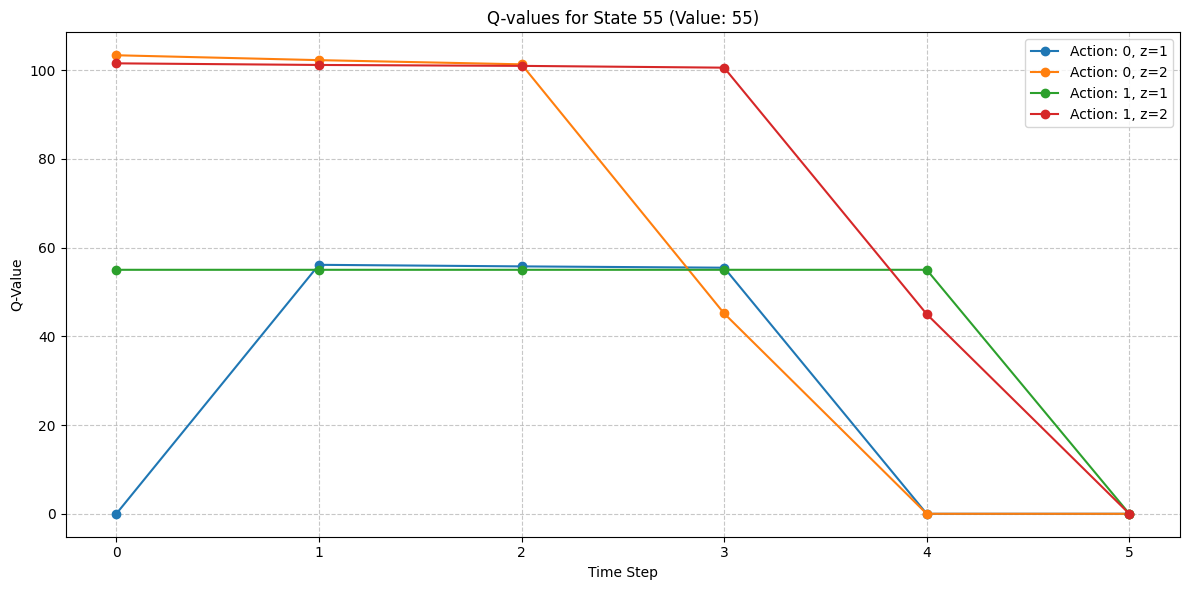

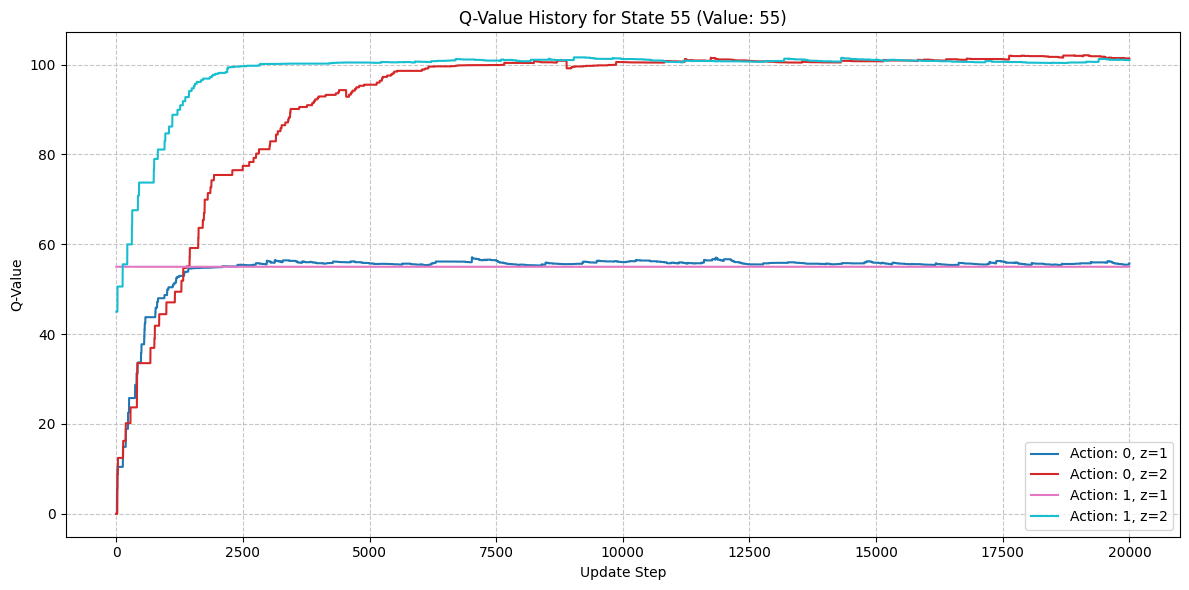

In [64]:
visualizer.plot_values(V_1_2, V_2_2, 55)
plot_q_values(Q_2, 55, env2)
visualizer.print_q_table_all_timesteps(Q_2, env2)
plot_q_history_for_state(history_2, state=55, time=2, env=env2)

(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Q-values for State 55 (Value: 55)'}, xlabel='Time Step', ylabel='Q-Value'>)

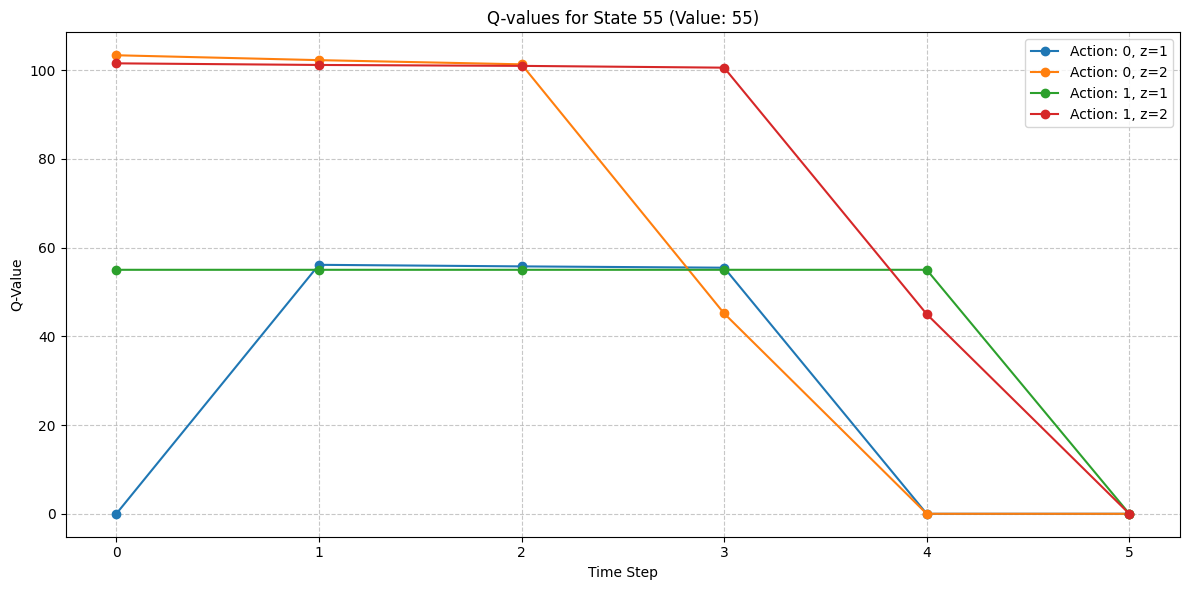

In [65]:
plot_q_values(Q_2, 55, env2)

In [66]:
class MarkovianDoubleOptimalStopping:
    def __init__(self, env):
        self.env = env
        self.N = env.horizon
        self.S = env.states
        self.cost = env.cost
        self.vN_1, self.vN_2 = self.dp()

    def dp(self):
        num_states = len(self.S)
        v = np.zeros((self.N + 1, 3, num_states))

        # Initialization
        v[0, 1, :] = -np.inf  # Can't stop once
        v[1, 2, :] = 0        # Can't stop twice at n=1

        # First stopping rule value function: v[n,1,s]
        for n in range(1, self.N):
            for s in self.S:
                x = v[n - 1, 1, s] - self.cost
                v[n, 1, s] = self.env.exp_max(self.N - n + 1, x, s)

        # Second stopping rule value function: v[n,2,s]
        for n in range(2, self.N + 1):
            for s in self.S:
                x = v[n - 1, 2, s] - v[n - 1, 1, s]
                expected = self.env.exp_max(self.N - n + 1, x, s)
                v[n, 2, s] = expected + v[n - 1, 1, s] - self.cost

        return v[:, 1, :], v[:, 2, :]

    def plot(self, state_idx=5):
        """Plot vN_1 and vN_2 over time for a fixed state"""
        if state_idx < 0 or state_idx >= len(self.env.states):
            raise IndexError(f"Invalid state index: {state_idx}. Must be in [0, {len(self.env.states) - 1}].")

        N_values = np.arange(self.env.horizon + 1)

        plt.figure(figsize=(8, 5))
        plt.plot(N_values[:-1], self.vN_1[:-1, state_idx], label="$v_{N,1}$", marker="o")
        plt.plot(N_values[2:], self.vN_2[2:, state_idx], label="$v_{N,2}$", marker="s")
        plt.xlabel("N (Time Horizon Remaining)")
        plt.ylabel("Value")
        plt.title(f"Optimal Stopping Values for State {state_idx}")
        plt.figtext(
            0.5,
            -0.1,
            f"Max offer={self.env.max_offer}, cost={self.env.cost}, horizon={self.env.horizon}",
            ha="center"
        )
        plt.legend()
        plt.grid()
        plt.show()

    def print(self, state_idx):
        if state_idx < 0 or state_idx >= len(self.env.states):
            raise IndexError(f"Invalid state index: {state_idx}. Must be in [0, {len(self.env.states) - 1}].")

        N_values = np.arange(self.env.horizon + 1)[::-1]
        table_data = [
            [N, v1, v2]
            for N, v1, v2 in zip(N_values, self.vN_1[::-1, state_idx], self.vN_2[::-1, state_idx])
        ]
        print(tabulate(table_data, headers=["N", "vN_1", "vN_2"], tablefmt="grid"))

    def get_values(self):
        V_1 = np.zeros((self.N + 1, len(self.env.states)))
        V_2 = np.zeros((self.N + 1, len(self.env.states)))

        for t in range(self.N + 1):
            for s in range(len(self.env.states)):
                V_1[t, s] = max(s, self.vN_1[self.N - (t + 1), s] - self.env.cost)
                V_2[t, s] = (
                    max(self.vN_2[self.N - (t + 1), s], s + self.vN_1[self.N - (t + 1), s])
                    - self.env.cost
                )

        return V_1, V_2


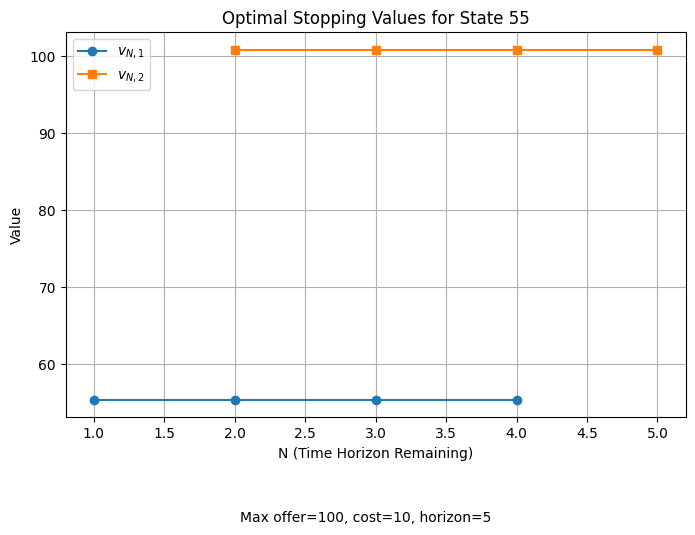

+-----+-----------+---------+
|   N |      vN_1 |    vN_2 |
+=====+===========+=========+
|   5 |    0      | 100.825 |
+-----+-----------+---------+
|   4 |   55.4125 | 100.825 |
+-----+-----------+---------+
|   3 |   55.4125 | 100.825 |
+-----+-----------+---------+
|   2 |   55.4125 | 100.825 |
+-----+-----------+---------+
|   1 |   55.4125 |   0     |
+-----+-----------+---------+
|   0 | -inf      |   0     |
+-----+-----------+---------+


In [67]:
vi_agent2 = MarkovianDoubleOptimalStopping(env2)
val1_2, val2_2 = vi_agent2.dp()
V_1_vi2, V_2_vi2 = vi_agent2.get_values()
vi_agent2.plot(state_idx=55)
vi_agent2.print(state_idx=55)

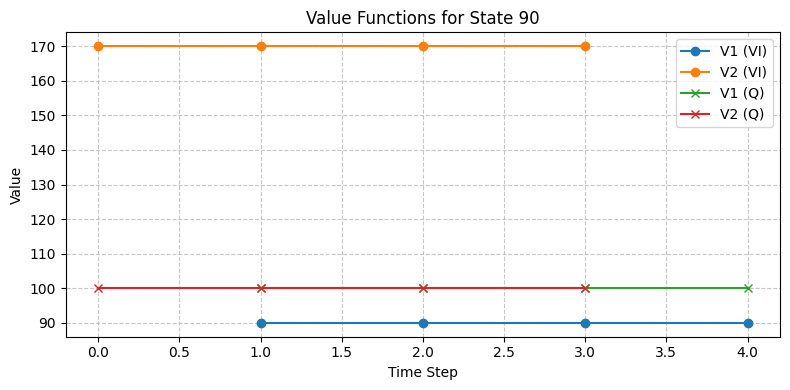

In [75]:
visualizer.plot_all_values(V_1_vi2, V_2_vi2, V_1_2, V_2_2, 90)

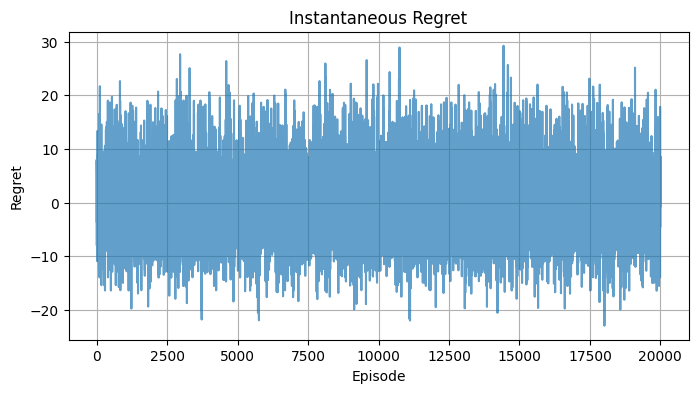

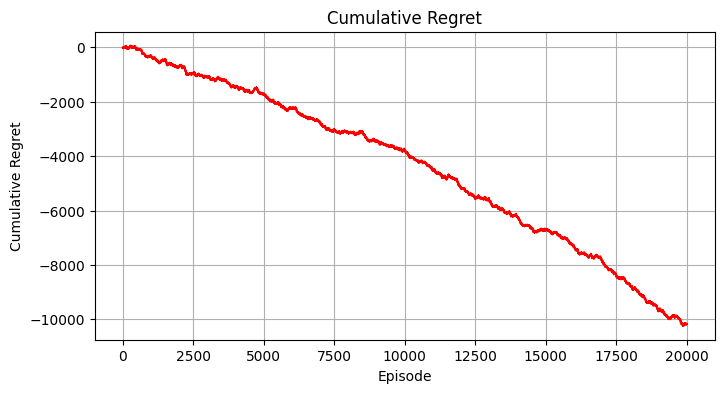

In [69]:
training_regret2,testing_regret2 = Q_agent_2.get_regret(V_2_2)
plt.figure(figsize=(8, 4))
plt.plot(testing_regret, alpha=0.7)
plt.xlabel("Episode")
plt.ylabel("Regret")
plt.title("Instantaneous Regret")
plt.grid(True)
plt.show()

cum_regret = np.cumsum(testing_regret2)
plt.figure(figsize=(8, 4))
plt.plot(cum_regret, color="red")
plt.xlabel("Episode")
plt.ylabel("Cumulative Regret")
plt.title("Cumulative Regret")
plt.grid(True)
plt.show()

In [70]:
import numpy as np
from tqdm import tqdm

# Environment class (required for context)
class MarkovianHouseSellingEnv:
    def __init__(self, horizon=10, cost=10, max_offer=100, alpha=1.0):
        self.horizon = horizon
        self.cost = cost
        self.max_offer = max_offer
        self.states = [i for i in range(max_offer + 1)]
        self.actions = [0, 1]  # 0: Accept, 1: Reject
        self.alpha = alpha
        self._init_probabilities()
        self._init_TPM()

    def reset(self):
        return np.random.choice(self.states, p=self.P)

    def _init_probabilities(self):
        self.P = np.zeros(self.max_offer + 1)
        mu = self.max_offer / 2
        sigma = np.sqrt(self.max_offer / 4)
        for i in range(self.max_offer + 1):
            self.P[i] = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
                -((i - mu) ** 2) / (2 * sigma**2)
            )
        self.P /= np.sum(self.P)

    def _init_TPM(self):
        self.TPM = np.zeros((self.max_offer + 1, self.max_offer + 1))
        self.P_cumsum = np.cumsum(self.P)
        for s in range(self.max_offer + 1):
            for s_prime in range(self.max_offer + 1):
                if s_prime < s:
                    self.TPM[s, s_prime] = 0
                elif s_prime == s:
                    self.TPM[s, s_prime] = self.P_cumsum[s]
                else:
                    self.TPM[s, s_prime] = self.P[s_prime]
            if np.sum(self.TPM[s]) > 0:
                self.TPM[s] /= np.sum(self.TPM[s])

    def get_next_state(self, s):
        return np.random.choice(self.states, p=self.TPM[s])

    def generate_sequence(self):
        sequence = [self.reset()]
        for _ in range(1, self.horizon):
            next_state = self.get_next_state(sequence[-1])
            sequence.append(next_state)
        return sequence

class QLearning_Modified_Init:
    # MODIFICATION: Added 'optimistic_init_value' to the constructor
    def __init__(self, env, epsilon=1, gamma=1, episodes=100000, alpha=0.1, c1=30, c2=60, optimistic_init_value=None):
        self.env = env
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.episodes = episodes
        self.c1 = c2
        self.c2 = c1
        self.actions = [0, 1]
        self.start_states = []
        self.ep_rewards = []

        # If no value is provided, default to the max possible offer.
        if optimistic_init_value is None:
            optimistic_init_value = self.env.max_offer

        self.Q = np.zeros(
            (self.env.horizon + 1, len(self.env.states), 2, 2)
        )
        self.Q_values_history = np.zeros(
            (self.episodes, self.env.horizon + 1, len(self.env.states), 2, 2)
        )

        self.Q[:self.env.horizon, :, :, 0] = optimistic_init_value
        # --- END OF MODIFICATION ---

        # This part remains the same, initializing the "Stop" action values
        for t in range(self.env.horizon):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    self.Q[t, s, z - 1, 1] = s - (z - 1) * self.env.cost

        # Terminal state penalties remain the same
        self.Q[self.env.horizon, :, 0, :] = -self.c1
        self.Q[self.env.horizon, :, 1, :] = -self.c2
        
        self.training_regret = []
        self.optimal_policy = None

    def greedy(self, t, s, z):
        max_val = np.max(self.Q[t, s, z - 1])
        max_actions = np.argwhere(self.Q[t, s, z - 1] == max_val).flatten()
        if len(max_actions) > 1:
            return np.random.choice(max_actions)
        else:
            return max_actions[0]

    def e_greedy(self, t, s, z):
        if np.random.rand() > self.epsilon:
            return self.greedy(t, s, z)
        return np.random.choice(self.actions)

    def reward(self, s, action, z):
        if action == 0:
            return 0
        else:
            if z == 2:
                return s - self.env.cost
            elif z == 1:
                return s
        return 0

    def simulate_episode(self):
        sequence = self.env.generate_sequence()
        self.start_states.append(sequence[0])
        z = 2
        ep_reward = 0
        for t in range(self.env.horizon):
            s = sequence[t]
            a = self.e_greedy(t, s, z)

            r = self.reward(s, a, z)
            ep_reward += r

            if t < self.env.horizon - 1:
                next_s = sequence[t + 1]
                next_z = z if a == 0 else z - 1

                if next_z > 0:
                    next_max_q = np.max(self.Q[t + 1, next_s, next_z - 1])
                else:
                    next_max_q = 0

                self.Q[t, s, z - 1, a] += self.alpha * (
                    r + self.gamma * next_max_q - self.Q[t, s, z - 1, a]
                )

                if a == 1 and next_z == 0:
                    break

                z = next_z
            else:
                self.Q[t, s, z - 1, a] += self.alpha * (r - self.Q[t, s, z - 1, a])
                break
        self.ep_rewards.append(ep_reward)
    
    def update_history(self, episode):
        self.Q_values_history[episode] = self.Q.copy()

    def learn(self):
        for i in tqdm(range(self.episodes), desc="Learning Progress"):
            self.simulate_episode()
            self.update_history(i)

        self.extract_policy()
        return self.Q, self.Q_values_history

    def extract_policy(self):
        policy = np.zeros((self.env.horizon, len(self.env.states), 2), dtype=int)
        for t in range(self.env.horizon):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    policy[t, s, z - 1] = np.argmax(self.Q[t, s, z - 1])
        self.optimal_policy = policy
        return policy

    def get_values(self):
        V_1 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        V_2 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                V_1[t, s] = max(self.Q[t, s, 0, a] for a in self.actions)
                V_2[t, s] = max(self.Q[t, s, 1, a] for a in self.actions)
        return V_1, V_2

    def get_regret(self, V_2):
        self.training_regret = np.zeros(self.episodes)
        self.testing_regret = np.zeros(self.episodes)
        for episode in range(self.episodes):
            self.training_regret[episode] = (
                V_2[0][self.start_states[episode]]
                - self.ep_rewards[episode]
            )
            sequence = self.env.generate_sequence()
            start_state = sequence[0]
            z = 2
            ep_reward = 0
            for t in range(self.env.horizon):
                s = sequence[t]
                a = self.greedy(t, s, z)

                r = self.reward(s, a, z)
                ep_reward += r

                if t < self.env.horizon - 1:
                    next_z = z if a == 0 else z - 1
                    if a == 1 and next_z == 0:
                        break
                    z = next_z
                else:
                    break
            self.testing_regret[episode] = (
                V_2[0][start_state] - ep_reward
            )
        return self.training_regret, self.testing_regret

    def get_average_rewards(self):
        self.average_rewards = np.zeros(self.episodes)
        average_reward = 0
        for episode in range(self.episodes):
            average_reward += (1 / (episode + 1)) * (
                self.ep_rewards[episode] - average_reward
            )
            self.average_rewards[episode] = average_reward
        return self.average_rewards

## With additional cost

Learning Progress: 100%|██████████| 20000/20000 [00:02<00:00, 7611.57it/s]


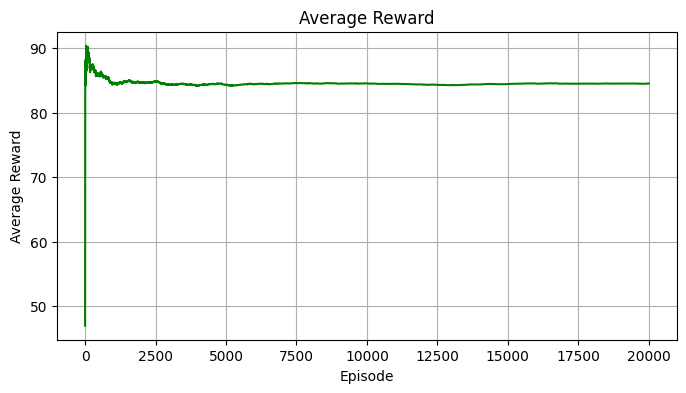

Average Reward: 84.534072803316
+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=1, A=0      | 100 | 100 | 100 | 100 | 100 | -60 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=1, A=1      |   0 |   0 |   0 |   0 |   0 | -60 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   |   0 |   1 |   2 |   3 |   4 |   5 |
+====================+=====+=====+=====+=====+=====+=====+
| S=0, z=2, A=0      | 100 | 100 | 100 | 100 | 100 | -30 |
+--------------------+-----+-----+-----+-----+-----+-----+

+--------------------+-----+-----+-----+-----+-----+-----+
| State, z, Action   

/var/folders/js/n7mnpc4915x2hstjlmdjm3_m0000gn/T/ipykernel_64796/1803107884.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_map = cm.get_cmap("tab10", num_lines)


(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Q-Value History for State 55 (Value: 55)'}, xlabel='Update Step', ylabel='Q-Value'>)

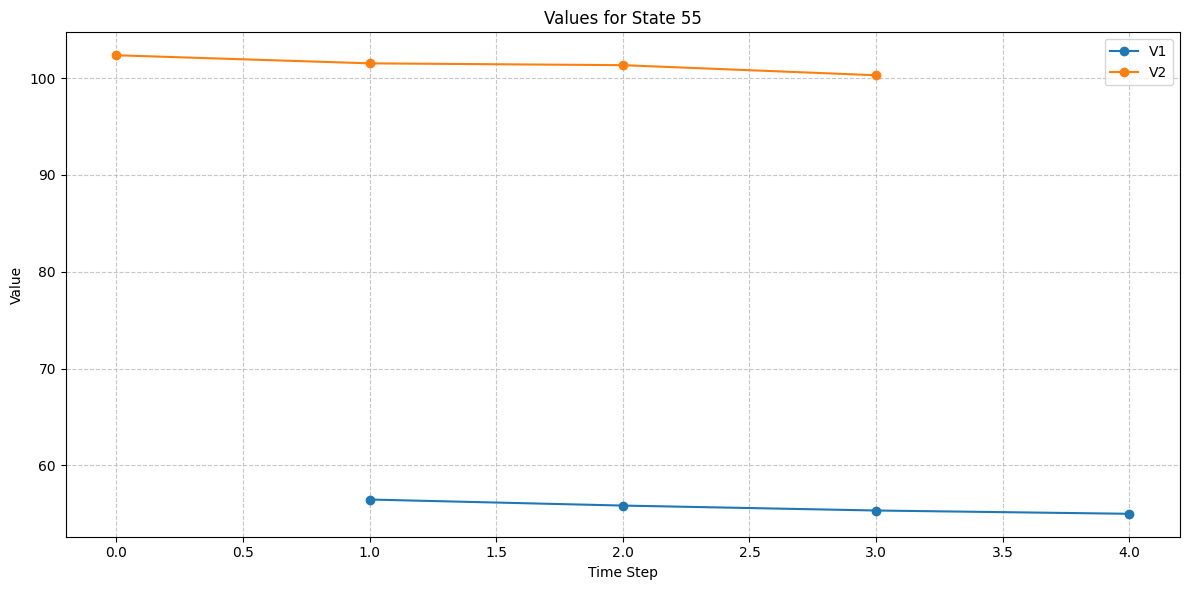

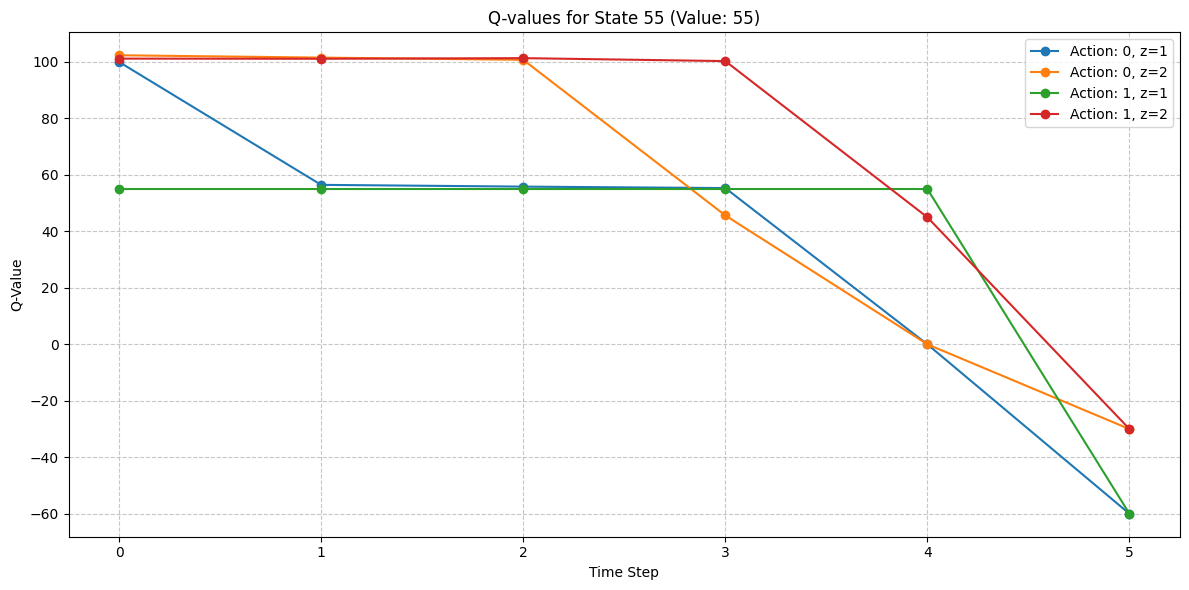

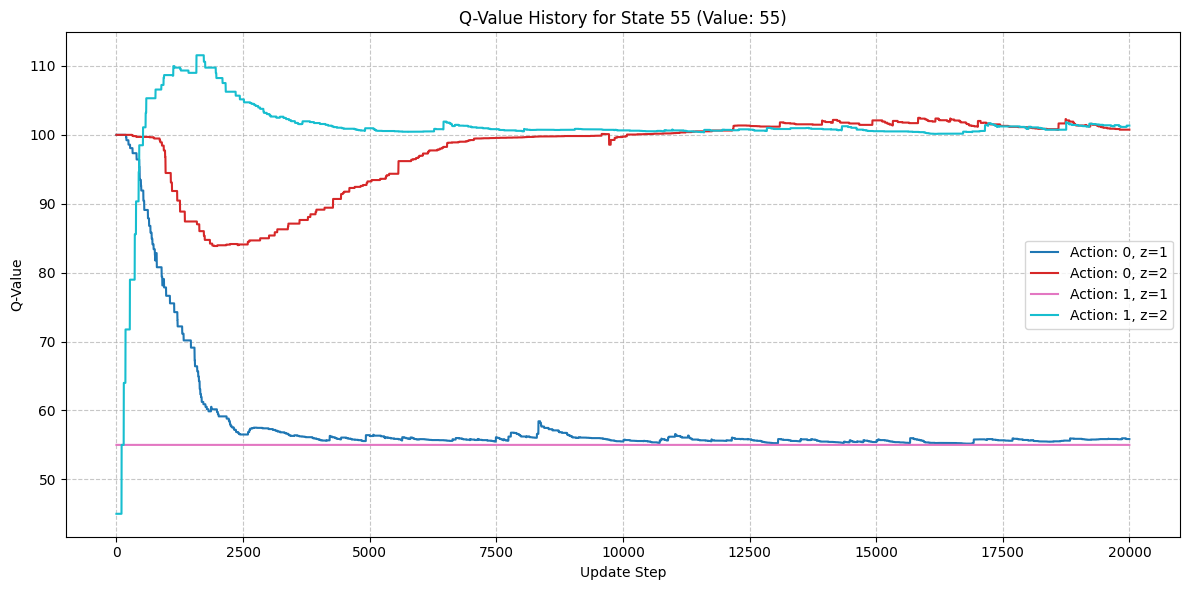

In [71]:
import matplotlib.pyplot as plt
env2 = MarkovianHouseSellingEnv(horizon=5, cost=10, max_offer=100)
Q_agent_2 = QLearning_Modified_Init(env2, episodes=20000)
Q_2, history_2 = Q_agent_2.learn()

V_1_2, V_2_2 = Q_agent_2.get_values()

average_rewards_2 = Q_agent_2.get_average_rewards()
plt.figure(figsize=(8, 4))
plt.plot(average_rewards_2, color="green")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("Average Reward")
plt.grid(True)
plt.show()
print("Average Reward:", np.mean(average_rewards_2[-100:]))

visualizer.plot_values(V_1_2, V_2_2, 55)
plot_q_values(Q_2, 55, env2)
visualizer.print_q_table_all_timesteps(Q_2, env2)
plot_q_history_for_state(history_2, state=55, time=2, env=env2)

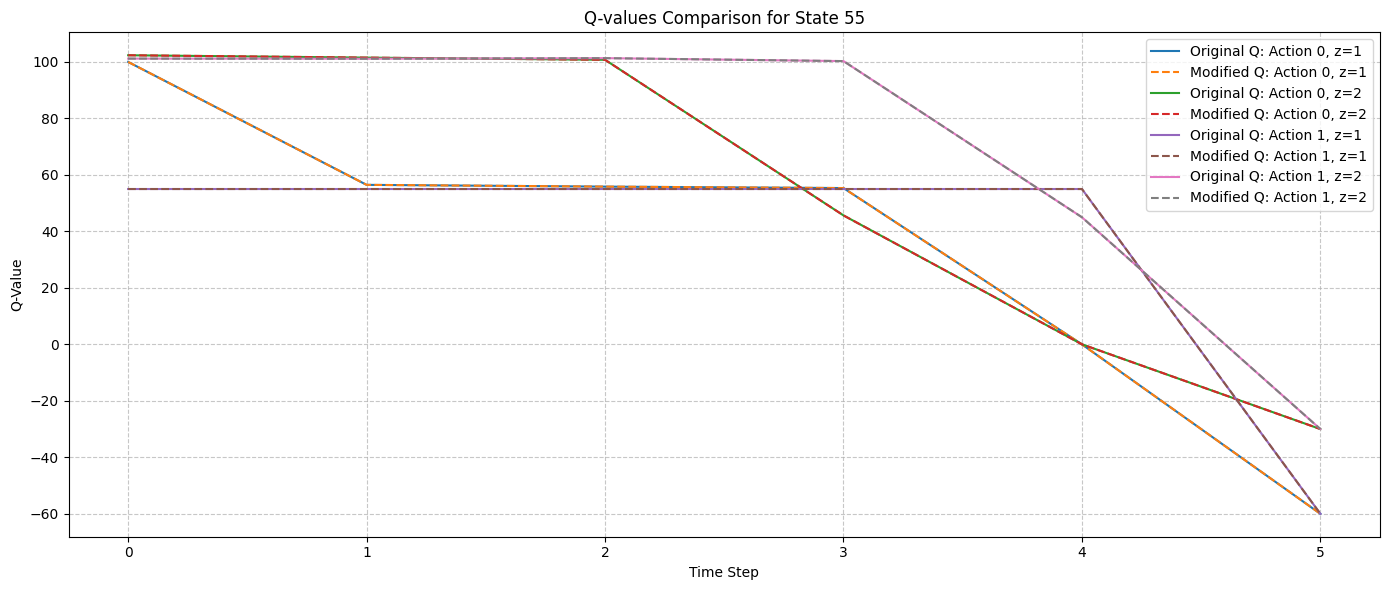

Q-values for every timestep for state 55 (Original QLearning):
t=0, z=1, action=0: Q=100.00
t=0, z=1, action=1: Q=55.00
t=0, z=2, action=0: Q=102.36
t=0, z=2, action=1: Q=101.18
t=1, z=1, action=0: Q=56.47
t=1, z=1, action=1: Q=55.00
t=1, z=2, action=0: Q=101.53
t=1, z=2, action=1: Q=101.12
t=2, z=1, action=0: Q=55.85
t=2, z=1, action=1: Q=55.00
t=2, z=2, action=0: Q=100.75
t=2, z=2, action=1: Q=101.34
t=3, z=1, action=0: Q=55.34
t=3, z=1, action=1: Q=55.00
t=3, z=2, action=0: Q=45.66
t=3, z=2, action=1: Q=100.30
t=4, z=1, action=0: Q=0.00
t=4, z=1, action=1: Q=55.00
t=4, z=2, action=0: Q=0.01
t=4, z=2, action=1: Q=45.00
t=5, z=1, action=0: Q=-60.00
t=5, z=1, action=1: Q=-60.00
t=5, z=2, action=0: Q=-30.00
t=5, z=2, action=1: Q=-30.00

Q-values for every timestep for state 55 (Modified QLearning):
t=0, z=1, action=0: Q=100.00
t=0, z=1, action=1: Q=55.00
t=0, z=2, action=0: Q=102.36
t=0, z=2, action=1: Q=101.18
t=1, z=1, action=0: Q=56.47
t=1, z=1, action=1: Q=55.00
t=1, z=2, action=0: 

In [72]:
# Compare Q-values for a given state (e.g., state_idx=55) from both QLearning and QLearning_Modified
state_idx = 55
action_names = env2.actions if hasattr(env2, 'actions') else env.actions
z_values = [1, 2]
horizon = Q_2.shape[0]

plt.figure(figsize=(14, 6))
for a_idx, action_name in enumerate(action_names):
    for z_index, z_val in enumerate(z_values):
        plt.plot(
            range(horizon),
            Q_2[:, state_idx, z_index, a_idx],
            label=f"Original Q: Action {action_name}, z={z_val}",
            linestyle='-',
        )
        plt.plot(
            range(horizon),
            Q_agent_2.Q[:, state_idx, z_index, a_idx],
            label=f"Modified Q: Action {action_name}, z={z_val}",
            linestyle='--',
        )
plt.xlabel("Time Step")
plt.ylabel("Q-Value")
plt.title(f"Q-values Comparison for State {state_idx}")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print(f"Q-values for every timestep for state {state_idx} (Original QLearning):")
for t in range(horizon):
    for z_index, z_val in enumerate(z_values):
        for a_idx, action_name in enumerate(action_names):
            print(f"t={t}, z={z_val}, action={action_name}: Q={Q_2[t, state_idx, z_index, a_idx]:.2f}")

print(f"\nQ-values for every timestep for state {state_idx} (Modified QLearning):")
for t in range(horizon):
    for z_index, z_val in enumerate(z_values):
        for a_idx, action_name in enumerate(action_names):
            print(f"t={t}, z={z_val}, action={action_name}: Q={Q_agent_2.Q[t, state_idx, z_index, a_idx]:.2f}")